# FIN vs Ignatov's CNN, 7 training users

- **train:** 7 random users, **validation:** 2 more random users (never user 30, who holds the phone rotated), **test:** the other 27
- **pretrained FIN, frozen:** imitates spectral entropy, autocorrelation peak and spectral peak on 30,000 warped copies of the 7 users' windows (no labels needed), then stays fixed;
- **Ignatov's CNN** (`ClassicML/cnn_wisdm.py`): Conv1D 196 filters of 12 -> max-pool 4 -> + his 40 statistical features -> Dense 1024 (L2) -> dropout -> softmax, Adam 5e-4; each window has its per-axis mean removed, the 40 features are standardised with the training users' statistics. The FIN sees no hand-made features
- both train with batch 256 (Ignatov used 200 and 50,000 iterations) for EPOCHS epochs, so an epoch is the same number of gradient steps
- **early stopping:** accuracy is tracked after every epoch on the training, validation and test users (dropout off); each model is scored on the test users at its best validation epoch, the last epoch is shown for reference

In [1]:
import os
import sys
import warnings
    
os.environ["KERAS_BACKEND"] = "torch"
warnings.filterwarnings("ignore")
FIN = os.path.dirname(os.getcwd())
sys.path[:0] = [FIN, os.path.join(FIN, "FIN-classifiers"), os.path.join(FIN, "data-processing")]

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from keras import layers, ops
from sklearn.metrics import f1_score, recall_score

import config as cfg
import wisdm_windowing as ww
from augmentation import make
from bilin_fin_temporal_plus_original import RhythmFIN, ignatov_features, targets

SEEDS = (0, 1, 2, 3, 4)
N_TRAIN = 7
N_VAL = 2
EPOCHS = 150  # long on purpose: the validation users pick the epoch
N_SYNTH = 30000

## Data

In [2]:
windows, users, labels = ww.window_raw()
candidates = np.setdiff1d(np.unique(users), [30])
stats = ignatov_features(windows)  # his 40 statistical features of every window
print(f"{len(windows)} windows, {len(np.unique(users))} users")

10367 windows, 36 users


## Models

In [3]:
class Accuracy(keras.callbacks.Callback):
    """Accuracy and cross-entropy loss on each named (x, y) set after every epoch (dropout off), and the
    weights of the best "val" epoch. Restores the RNG so training is unaffected."""

    def __init__(self, **sets):
        super().__init__()
        self.sets, self.curves = sets, {key: [] for name in sets for key in (name, name + " loss")}
        self.best_epoch, self.best_weights = 0, None

    def on_epoch_end(self, epoch, logs=None):
        rng = torch.random.get_rng_state()
        for name, (x, y) in self.sets.items():
            prob = self.model.predict(x, batch_size=1024, verbose=0)
            self.curves[name].append(float(np.mean(prob.argmax(axis=1) == y)))
            self.curves[name + " loss"].append(float(-np.mean(np.log(np.clip(prob[np.arange(len(y)), y], 1e-7, 1)))))
        torch.random.set_rng_state(rng)
        if self.curves["val"][-1] > max(self.curves["val"][:-1], default=-1):
            self.best_epoch, self.best_weights = epoch + 1, self.model.get_weights()


def pretrain(axes, seed):
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    y = targets(axes)
    fin.compile(optimizer=keras.optimizers.Adam(cfg.FIN_LR), loss="mse")
    fin.fit(axes, ((y - y.mean(0)) / y.std(0)).astype(np.float32),
            epochs=cfg.FIN_EPOCHS, batch_size=cfg.BATCH_SIZE, verbose=0)
    return fin.get_weights()


class FINClassifier(keras.Model):

    def __init__(self, fin, **kw):
        super().__init__(**kw)
        self.fin = fin
        self.hidden = layers.Dense(cfg.HEAD_WIDTH, activation="relu")
        self.out = layers.Dense(cfg.N_CLASSES, activation="softmax")

    def call(self, x):
        h = ops.concatenate([self.fin.embed(x[:, i, :]) for i in range(len(cfg.AXES))], axis=1)
        return self.out(self.hidden(h))


def ignatov_cnn(n_features):
    """Ignatov's CNN as in ClassicML/cnn_wisdm.py."""
    init = dict(kernel_initializer=keras.initializers.TruncatedNormal(stddev=0.01),
                bias_initializer=keras.initializers.Constant(0.01))
    # his loss is summed over a batch of 200 and adds 5e-4 * sum(w^2) / 2; per window that is this L2
    l2 = keras.regularizers.L2(5e-4 / 2 / 200)
    signal = keras.Input((cfg.SEGMENT, len(cfg.AXES)))
    features = keras.Input((n_features,))
    h = layers.Conv1D(196, 12, padding="same", activation="relu", **init)(signal)
    h = layers.MaxPooling1D(4, padding="same")(h)
    h = layers.Concatenate()([layers.Flatten()(h), features])
    h = layers.Dense(1024, activation="relu", kernel_regularizer=l2, bias_regularizer=l2, **init)(h)
    h = layers.Dropout(0.15)(h)  # his code feeds keep_prob = 0.15 (85 % dropped), most likely meant as a 15 % drop
    return keras.Model([signal, features], layers.Dense(cfg.N_CLASSES, activation="softmax", **init)(h))


def fit(model, x, lr, tr, va, te, batch_size=cfg.BATCH_SIZE):
    """x: the model input for every window (an array or a list of arrays). Returns the test predictions at the
    best validation epoch and at the last epoch, the accuracy curves and the best epoch."""
    pick = lambda m: [a[m] for a in x] if isinstance(x, list) else x[m]
    track = Accuracy(train=(pick(tr), labels[tr]), val=(pick(va), labels[va]), test=(pick(te), labels[te]))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy")
    model.fit(pick(tr), labels[tr], epochs=EPOCHS, batch_size=batch_size, verbose=0, callbacks=[track])
    last = model.predict(pick(te), batch_size=1024, verbose=0).argmax(axis=1)
    model.set_weights(track.best_weights)
    best = model.predict(pick(te), batch_size=1024, verbose=0).argmax(axis=1)
    return best, last, track.curves, track.best_epoch


def run_fin(tr, va, te, seed):
    weights = pretrain(make(N_SYNTH, seed, windows[tr].reshape(-1, cfg.SEGMENT)), seed)
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    fin(np.zeros((1, cfg.SEGMENT), np.float32))
    fin.set_weights(weights)
    fin.trainable = False
    keras.utils.set_random_seed(seed)
    return fit(FINClassifier(fin), windows, cfg.HEAD_LR, tr, va, te)


def run_ignatov(tr, va, te, seed):
    x = windows.transpose(0, 2, 1)  # (window, time, axis)
    x = (x - x.mean(axis=1, keepdims=True)).astype(np.float32)  # per-window, per-axis mean removed
    mu, sd = stats[tr].mean(0), stats[tr].std(0)
    f = ((stats - mu) / np.where(sd < 1e-8, 1.0, sd)).astype(np.float32)
    keras.utils.set_random_seed(seed)
    return fit(ignatov_cnn(f.shape[1]), [x, f], 5e-4, tr, va, te)

## Experiment

In [4]:
MODELS = {"pretrained FIN, frozen": run_fin, "Ignatov CNN + 40 features": run_ignatov}
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834"]))

rows, curves, best_epochs = [], {m: {} for m in MODELS}, {m: [] for m in MODELS}
for seed in SEEDS:
    picked = np.random.default_rng(seed).choice(candidates, N_TRAIN + N_VAL, replace=False)
    tr, va = np.isin(users, picked[:N_TRAIN]), np.isin(users, picked[N_TRAIN:])
    te = ~(tr | va)
    for model, run in MODELS.items():
        best, last, curve, epoch = run(tr, va, te, seed)
        for split in curve:
            curves[model].setdefault(split, []).append(curve[split])
        best_epochs[model].append(epoch)
        truth = labels[te]
        recall = recall_score(truth, best, labels=range(cfg.N_CLASSES), average=None, zero_division=0)
        rows.append({"seed": seed, "train users": sorted(picked[:N_TRAIN].tolist()),
                     "val users": sorted(picked[N_TRAIN:].tolist()), "model": model, "best epoch": epoch,
                     "train accuracy": curve["train"][epoch - 1], "val accuracy": curve["val"][epoch - 1],
                     "accuracy": np.mean(best == truth), "macro F1": f1_score(truth, best, average="macro"),
                     "accuracy, last epoch": np.mean(last == truth), **dict(zip(cfg.ACTIVITIES, recall))})
    print(f"seed {seed}: train {sorted(picked[:N_TRAIN].tolist())}, val {sorted(picked[N_TRAIN:].tolist())} done")
results = pd.DataFrame(rows)

seed 0: train [3, 7, 9, 10, 15, 18, 23], val [1, 2] done
seed 1: train [2, 5, 9, 13, 15, 29, 34], val [22, 28] done
seed 2: train [4, 8, 9, 12, 13, 23, 35], val [15, 27] done
seed 3: train [2, 3, 8, 20, 26, 29, 32], val [6, 22] done
seed 4: train [3, 16, 20, 27, 31, 34, 36], val [26, 33] done


In [5]:
acc = results.pivot(index="seed", columns="model", values="accuracy")
columns = ["best epoch", "train accuracy", "val accuracy", "accuracy", "macro F1", "accuracy, last epoch"]
display(results.groupby("model")[columns].agg(["mean", "std"]).loc[list(MODELS)].round(4),
        results.pivot(index="seed", columns="model", values=["best epoch", "accuracy"]).round(4),
        (acc["pretrained FIN, frozen"] - acc["Ignatov CNN + 40 features"]).rename("FIN - Ignatov").round(4),
        results.groupby("model")[list(cfg.ACTIVITIES)].mean().loc[list(MODELS)].round(3))

best epoch          train accuracy          \
                                mean      std           mean     std   
model                                                                  
pretrained FIN, frozen          38.2  54.3755         0.9702  0.0211   
Ignatov CNN + 40 features       19.0  23.8013         0.9436  0.0691   

                          val accuracy         accuracy         macro F1  \
                                  mean     std     mean     std     mean   
model                                                                      
pretrained FIN, frozen          0.8826  0.0362   0.8272  0.0354   0.7182   
Ignatov CNN + 40 features       0.8874  0.0281   0.7467  0.0446   0.6512   

                                  accuracy, last epoch          
                              std                 mean     std  
model                                                           
pretrained FIN, frozen     0.0337               0.8180  0.0408  
Ignatov CNN + 40 features  0.0953               0.7323  0.0452

best epoch                         \
model Ignatov CNN + 40 features pretrained FIN, frozen   
seed                                                     
0                           5.0                  134.0   
1                          61.0                    7.0   
2                           6.0                   30.0   
3                          15.0                    7.0   
4                           8.0                   13.0   

                       accuracy                         
model Ignatov CNN + 40 features pretrained FIN, frozen  
seed                                                    
0                        0.7649                 0.8549  
1                        0.7911                 0.7709  
2                        0.7234                 0.8593  
3                        0.6804                 0.8300  
4                        0.7736                 0.8211

seed
0    0.0900
1   -0.0202
2    0.1359
3    0.1496
4    0.0475
Name: FIN - Ignatov, dtype: float64

,Jogging,Walking,Upstairs,Downstairs,Sitting,Standing
model,,,,,,
"pretrained FIN, frozen",0.880,0.934,0.527,0.654,0.715,0.658
Ignatov CNN + 40 features,0.867,0.833,0.322,0.344,0.879,0.750


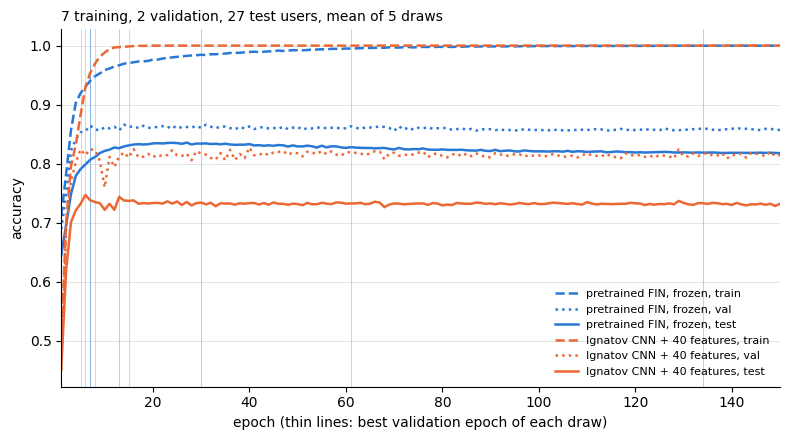

In [6]:
epochs = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
for model, color in COLORS.items():
    for split, style in (("train", "--"), ("val", ":"), ("test", "-")):
        mean = np.mean(curves[model][split], axis=0)
        ax.plot(epochs, mean, color=color, linewidth=1.8, linestyle=style, label=f"{model}, {split}")
    for epoch in best_epochs[model]:
        ax.axvline(epoch, color=color, linewidth=0.6, alpha=0.4)
ax.set_xlabel("epoch (thin lines: best validation epoch of each draw)")
ax.set_ylabel("accuracy")
ax.set_xlim(1, EPOCHS)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.6)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title(f"{N_TRAIN} training, {N_VAL} validation, {36 - N_TRAIN - N_VAL} test users, "
             f"mean of {len(SEEDS)} draws", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

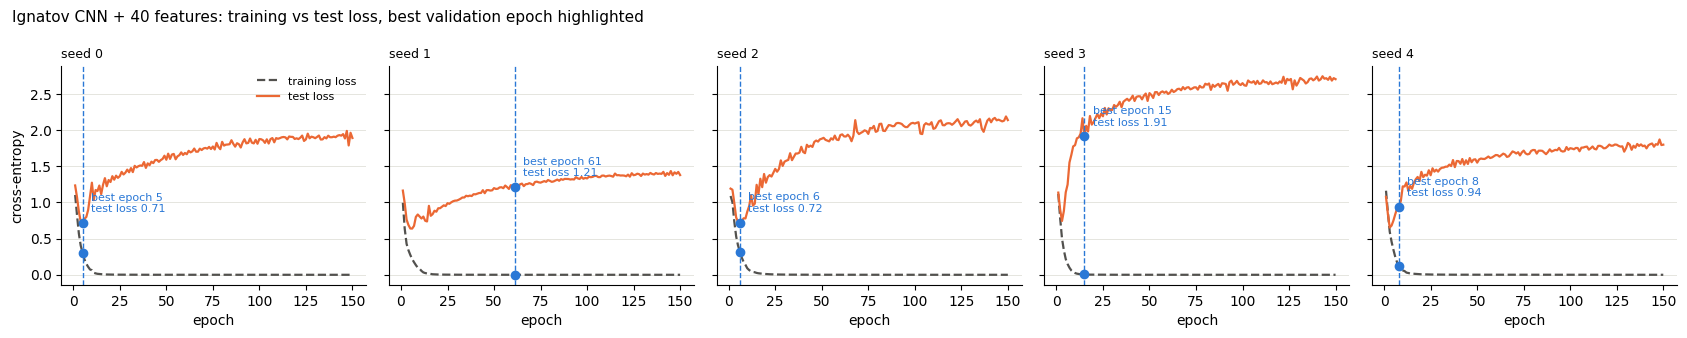

In [7]:
model = "Ignatov CNN + 40 features"
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, len(SEEDS), figsize=(3.4 * len(SEEDS), 3.4), sharey=True, squeeze=False)
for ax, seed, train, test, best in zip(axes[0], SEEDS, curves[model]["train loss"], curves[model]["test loss"],
                                       best_epochs[model]):
    ax.plot(epochs, train, color="#52514e", linewidth=1.6, linestyle="--", label="training loss")
    ax.plot(epochs, test, color="#eb6834", linewidth=1.6, label="test loss")
    ax.axvline(best, color="#2a78d6", linewidth=1, linestyle="--")
    ax.scatter([best, best], [train[best - 1], test[best - 1]], color="#2a78d6", zorder=3)
    ax.annotate(f"best epoch {best}\ntest loss {test[best - 1]:.2f}", (best, test[best - 1]), xytext=(6, 8),
                textcoords="offset points", fontsize=8, color="#2a78d6")
    ax.set_title(f"seed {seed}", fontsize=9, loc="left")
    ax.set_xlabel("epoch")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.6)
axes[0, 0].set_ylabel("cross-entropy")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle(f"{model}: training vs test loss, best validation epoch highlighted", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()